In [1]:
# ---------------------------------------------------------
# Practical 3B: ECG Anomaly Detection
# Using 1D Convolutional Autoencoder
# ---------------------------------------------------------

# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)


In [2]:
# Step 2: Load the ECG dataset

# header=None because the CSV has no column names
data = pd.read_csv("ecg.csv", header=None)

print("Dataset Shape:", data.shape)
print("\nFirst five records:")
print(data.head())

Dataset Shape: (4998, 141)

First five records:
        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       13

In [3]:
# Step 3: Separate ECG signals and labels

# First 140 columns contain ECG signal values
X = data.iloc[:, :-1].values

# Last column contains class labels
y = data.iloc[:, -1].values.astype(int)

print("\nECG Signal Shape:", X.shape)
print("Labels:", np.unique(y, return_counts=True))


ECG Signal Shape: (4998, 140)
Labels: (array([0, 1]), array([2079, 2919]))


In [4]:
# ASSUMPTION:
# Class 1 = Normal
# Class 0 = Anomaly
# Change this value if your dataset documentation says otherwise.

NORMAL_LABEL = 1

# Step 4: Split data into training and testing sets

X_train_all, X_test, y_train_all, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [5]:
# Step 5: Keep only normal signals for training

X_train_normal = X_train_all[
    y_train_all == NORMAL_LABEL
]

In [6]:
# Split normal training signals into training and validation
X_train_normal, X_val_normal = train_test_split(
    X_train_normal,
    test_size=0.1,
    random_state=42
)

print("\nNormal Training Shape:", X_train_normal.shape)
print("Normal Validation Shape:", X_val_normal.shape)
print("Testing Shape:", X_test.shape)



Normal Training Shape: (2101, 140)
Normal Validation Shape: (234, 140)
Testing Shape: (1000, 140)


In [7]:
# Step 6: Normalize ECG signals

scaler = MinMaxScaler()

# Fit scaler only on normal training data
X_train_normal = scaler.fit_transform(X_train_normal)

# Transform validation and test data
X_val_normal = scaler.transform(X_val_normal)
X_test = scaler.transform(X_test)

In [8]:
# Step 7: Reshape data for Conv1D

# Conv1D requires:
# (Number of samples, Time steps, Channels)

X_train_normal = X_train_normal.reshape(
    -1, 140, 1
)

X_val_normal = X_val_normal.reshape(
    -1, 140, 1
)

X_test = X_test.reshape(
    -1, 140, 1
)

print("\nReshaped Training Data:", X_train_normal.shape)
print("Reshaped Testing Data:", X_test.shape)


Reshaped Training Data: (2101, 140, 1)
Reshaped Testing Data: (1000, 140, 1)


In [9]:
# Step 8: Build Convolutional Autoencoder

model = keras.Sequential([

    layers.Input(shape=(140, 1)),

    # Encoder
    layers.Conv1D(
        32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling1D(
        pool_size=2,
        padding="same"
    ),

    layers.Conv1D(
        16,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling1D(
        pool_size=2,
        padding="same"
    ),

    # Decoder
    layers.Conv1D(
        16,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    layers.UpSampling1D(size=2),

    layers.Conv1D(
        32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    layers.UpSampling1D(size=2),

    # Reconstruct original ECG signal
    layers.Conv1D(
        1,
        kernel_size=3,
        activation="linear",
        padding="same"
    )
])

In [10]:
# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 140, 32)             │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 70, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 70, 16)              │           1,552 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 35, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 35, 16)              │             784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d (UpSampling1D)         │ (None, 70, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 70, 32)              │           1,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d_1 (UpSampling1D)       │ (None, 140, 32)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ (None, 140, 1)              │              97 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,129 (16.13 KB)

 Trainable params: 4,129 (16.13 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Step 9: Compile the model

model.compile(
    optimizer="adam",
    loss="mse"
)


In [12]:
# Step 10: Train the Autoencoder using normal ECG signals

history = model.fit(
    X_train_normal,
    X_train_normal,

    epochs=20,
    batch_size=64,

    validation_data=(
        X_val_normal,
        X_val_normal
    ),

    shuffle=True
)


Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0792 - val_loss: 0.0113
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0102 - val_loss: 0.0080
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0057 - val_loss: 0.0049
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0041 - val_loss: 0.0039
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0030 - val_loss: 0.0026
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0023 - val_loss: 0.0022
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0020 - val_loss: 0.0021
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 9/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0017 - val_loss: 0.0018
Epoch 10/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 11/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0016 - val_loss: 0.0017
Epoch 12/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.001

In [13]:
# Step 11: Calculate reconstruction error on normal validation data

val_reconstructed = model.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_reconstructed),
    axis=(1, 2)
)


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


In [15]:
# Set threshold using 99th percentile
threshold = np.percentile(val_errors, 99)

print("\nAnomaly Detection Threshold:", threshold)



Anomaly Detection Threshold: 0.005030271151665138


In [16]:
# Step 12: Calculate reconstruction error on test data

test_reconstructed = model.predict(X_test)

test_errors = np.mean(
    np.square(X_test - test_reconstructed),
    axis=(1, 2)
)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


In [17]:
# Step 13: Detect anomalies

# Error greater than threshold = Anomaly
y_pred = (test_errors > threshold).astype(int)

In [18]:
# Convert actual labels:
# Normal class becomes 0
# Anomaly class becomes 1

y_test_anomaly = (
    y_test != NORMAL_LABEL
).astype(int)


In [19]:

# Step 14: Evaluate the model

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_anomaly, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test_anomaly,
        y_pred,
        zero_division=0
    )
)

print("Precision:", precision_score(
    y_test_anomaly, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test_anomaly, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_anomaly, y_pred, zero_division=0
))


Confusion Matrix:
[[581   3]
 [410   6]]

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.99      0.74       584
           1       0.67      0.01      0.03       416

    accuracy                           0.59      1000
   macro avg       0.63      0.50      0.38      1000
weighted avg       0.62      0.59      0.44      1000

Precision: 0.6666666666666666
Recall: 0.014423076923076924
F1 Score: 0.02823529411764706


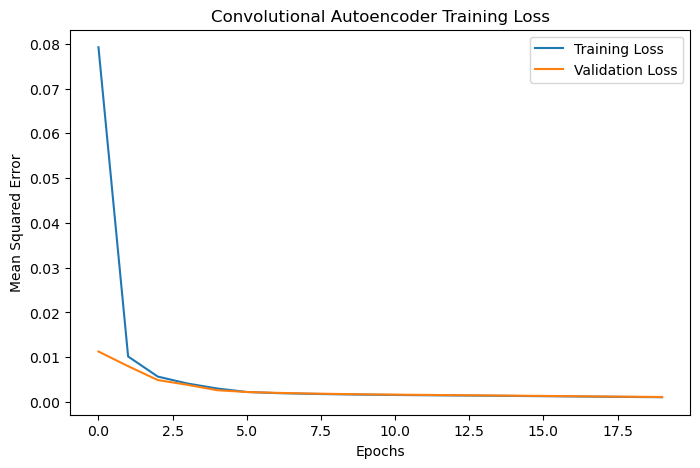

In [21]:
# Step 15: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Convolutional Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()


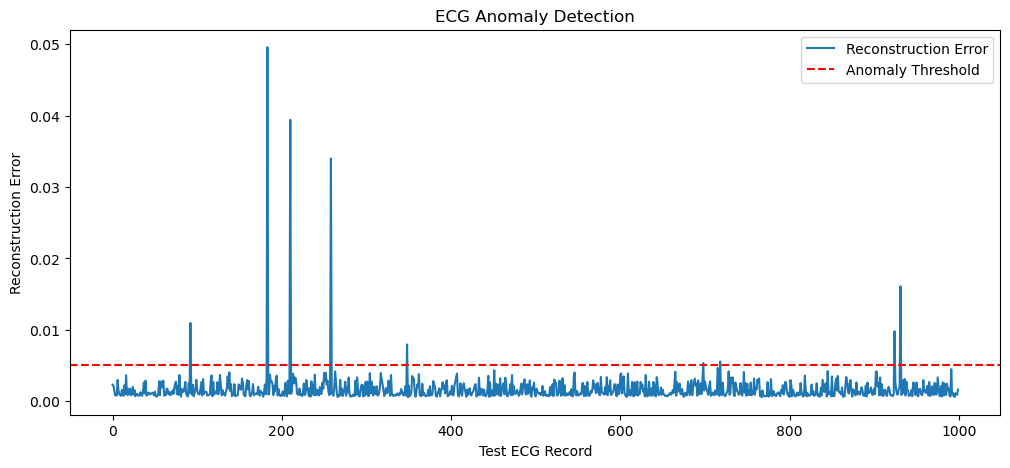

In [22]:
# Step 16: Plot reconstruction errors and threshold

plt.figure(figsize=(12, 5))

plt.plot(
    test_errors,
    label="Reconstruction Error"
)

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.title("ECG Anomaly Detection")
plt.xlabel("Test ECG Record")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()


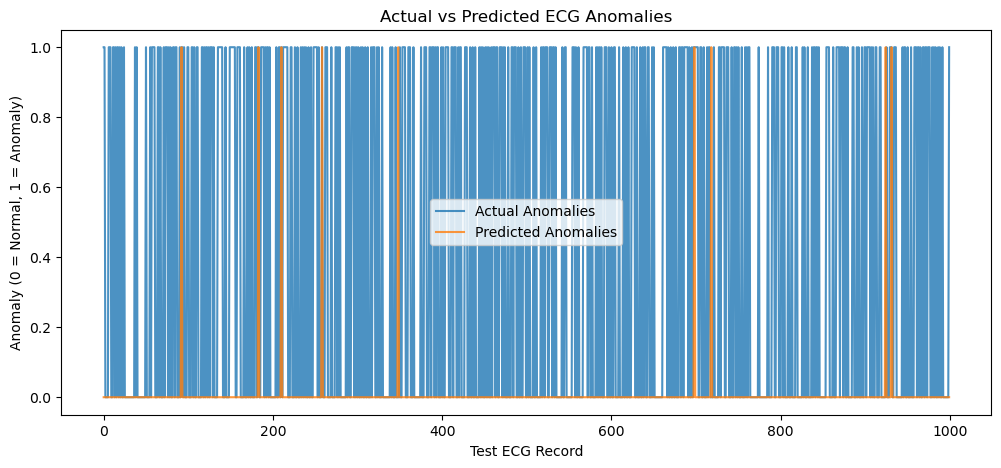

In [23]:
# Step 17: Display actual and predicted anomalies

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_anomaly,
    label="Actual Anomalies",
    alpha=0.8
)

plt.plot(
    y_pred,
    label="Predicted Anomalies",
    alpha=0.8
)

plt.title("Actual vs Predicted ECG Anomalies")
plt.xlabel("Test ECG Record")
plt.ylabel("Anomaly (0 = Normal, 1 = Anomaly)")
plt.legend()
plt.show()

In [24]:
# Step 18: Display final results

print("\nTotal Test Records:", len(y_test_anomaly))
print("Actual Anomalies:", np.sum(y_test_anomaly))
print("Predicted Anomalies:", np.sum(y_pred))

print("\nPractical Completed Successfully!")



Total Test Records: 1000
Actual Anomalies: 416
Predicted Anomalies: 9

Practical Completed Successfully!
